In [1]:
import h5py 

with h5py.File("../data/raw/test.h5", "r") as f:
    
    def mostrar(nombre, objeto):
        if isinstance(objeto, h5py.Dataset):
            print(f"{nombre:40s} forma {objeto.shape}  tipo {objeto.dtype}")
    f.visititems(mostrar)


table/_i_table/index/abounds             forma (384,)  tipo int64
table/_i_table/index/bounds              forma (3, 127)  tipo int64
table/_i_table/index/indices             forma (3, 131072)  tipo uint32
table/_i_table/index/indicesLR           forma (131072,)  tipo uint32
table/_i_table/index/mbounds             forma (384,)  tipo int64
table/_i_table/index/mranges             forma (3,)  tipo int64
table/_i_table/index/ranges              forma (3, 2)  tipo int64
table/_i_table/index/sorted              forma (3, 131072)  tipo int64
table/_i_table/index/sortedLR            forma (131201,)  tipo int64
table/_i_table/index/zbounds             forma (384,)  tipo int64
table/table                              forma (404000,)  tipo [('index', '<i8'), ('values_block_0', '<f4', (804,)), ('values_block_1', '<i8', (2,))]


In [2]:
pip install hdf5plugin



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import h5py
import hdf5plugin        # <-- nueva: registra Blosc y otros descompresores
import numpy as np

with h5py.File("../data/raw/test.h5", "r") as f:
    filas = f["table/table"][0:100_000]

numeros = filas["values_block_0"]
etiquetas = filas["values_block_1"]

print(numeros.shape, numeros.dtype)
print(etiquetas.shape)
print(f"Memoria: {numeros.nbytes / 1e6:.0f} MB")
print("Valores de las etiquetas:", np.unique(etiquetas[:, 0]), np.unique(etiquetas[:, 1]))

(100000, 804) float32
(100000, 2)
Memoria: 322 MB
Valores de las etiquetas: [1] [0 1]


In [4]:
y = etiquetas[:, 1]
print("Jets top:", (y == 1).sum(), "   Jets QCD:", (y == 0).sum())

Jets top: 49430    Jets QCD: 50570


In [5]:
p = numeros[:, :800].reshape(-1, 200, 4)
E, px, py, pz = p[..., 0], p[..., 1], p[..., 2], p[..., 3]

hay = E > 0
masa2 = E[hay]**2 - (px[hay]**2 + py[hay]**2 + pz[hay]**2)
print("Partículas reales:", hay.sum())
print("Fracción con E² ≥ p²:", np.mean(masa2 > -1e-3 * E[hay]**2))

Partículas reales: 4897415
Fracción con E² ≥ p²: 1.0


pT del jet: de 550 a 650 GeV


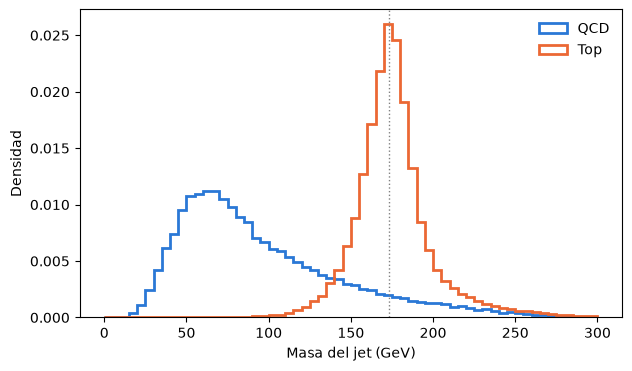

In [6]:
import matplotlib.pyplot as plt

# guardar en float32, calcular en float64 
E64, px64, py64, pz64 = (c.astype(np.float64) for c in (E, px, py, pz))

jet_E  = E64.sum(axis=1)
jet_px = px64.sum(axis=1)
jet_py = py64.sum(axis=1)
jet_pz = pz64.sum(axis=1)

jet_pt   = np.sqrt(jet_px**2 + jet_py**2)
jet_masa = np.sqrt(np.clip(jet_E**2 - (jet_px**2 + jet_py**2 + jet_pz**2), 0, None))
n_part   = hay.sum(axis=1)

print(f"pT del jet: de {jet_pt.min():.0f} a {jet_pt.max():.0f} GeV")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 300, 61)
ax.hist(jet_masa[y == 0], bins, histtype="step", lw=2, color="#2a78d6", label="QCD", density=True)
ax.hist(jet_masa[y == 1], bins, histtype="step", lw=2, color="#eb6834", label="Top", density=True)
ax.axvline(173, color="gray", ls=":", lw=1)
ax.set_xlabel("Masa del jet (GeV)")
ax.set_ylabel("Densidad")
ax.legend(frameon=False)
plt.show()

AUC usando solo la masa: 0.927


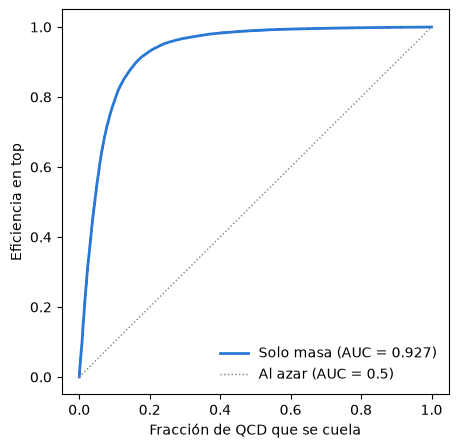

In [7]:
from sklearn.metrics import roc_auc_score, roc_curve

# más próximo a 173 GeV
puntaje_masa = -np.abs(jet_masa - 173)

auc = roc_auc_score(y, puntaje_masa)
print(f"AUC usando solo la masa: {auc:.3f}")

fpr, tpr, _ = roc_curve(y, puntaje_masa)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color="#2a78d6", lw=2, label=f"Solo masa (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1, label="Al azar (AUC = 0.5)")
ax.set_xlabel("Fracción de QCD que se cuela")
ax.set_ylabel("Eficiencia en top")
ax.legend(frameon=False)
plt.show()

In [8]:
for ancho in [5, 10, 20, 40, 80, 150]:
    dentro = np.abs(jet_masa - 173) < ancho
    efic_top = dentro[y == 1].mean()
    cuela_qcd = dentro[y == 0].mean()
    print(f"ventana ±{ancho:3d} GeV:   top dentro = {efic_top:.2f}   QCD dentro = {cuela_qcd:.2f}")

ventana ±  5 GeV:   top dentro = 0.25   QCD dentro = 0.02
ventana ± 10 GeV:   top dentro = 0.46   QCD dentro = 0.04
ventana ± 20 GeV:   top dentro = 0.72   QCD dentro = 0.08
ventana ± 40 GeV:   top dentro = 0.91   QCD dentro = 0.17
ventana ± 80 GeV:   top dentro = 0.98   QCD dentro = 0.41
ventana ±150 GeV:   top dentro = 1.00   QCD dentro = 0.99


In [9]:
# 1. Coordenadas de cada partícula
pt_i = np.sqrt(px64**2 + py64**2)
with np.errstate(divide="ignore", invalid="ignore"):
    eta_i = np.where(hay, np.arcsinh(pz64 / pt_i), 0.0)
phi_i = np.arctan2(py64, px64)

# 2. Coordenadas del eje del jet
jet_eta = np.arcsinh(jet_pz / jet_pt)
jet_phi = np.arctan2(jet_py, jet_px)

# 3. Distancia de cada partícula al eje
deta = eta_i - jet_eta[:, None]
dphi = (phi_i - jet_phi[:, None] + np.pi) % (2 * np.pi) - np.pi
dR = np.where(hay, np.hypot(deta, dphi), 0.0)

# 4. Las tres variables de subestructura
pt_total   = pt_i.sum(axis=1)
anchura    = (pt_i * dR).sum(axis=1) / pt_total
frac_lider = pt_i.max(axis=1) / pt_total

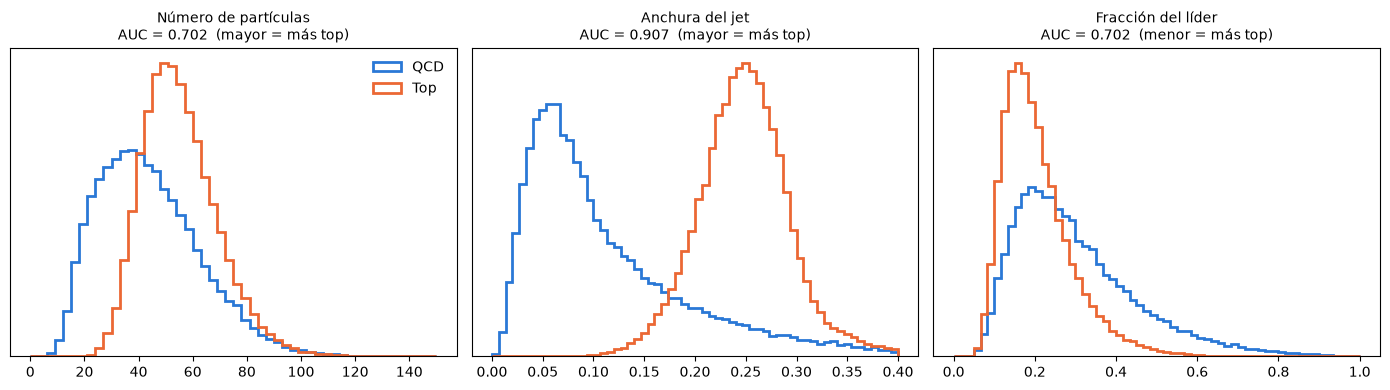

In [10]:
variables = {
    "Número de partículas": (n_part,     np.arange(0, 151, 3)),
    "Anchura del jet":      (anchura,    np.linspace(0, 0.4, 61)),
    "Fracción del líder":   (frac_lider, np.linspace(0, 1, 61)),
}

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (nombre, (valores, bins)) in zip(ejes, variables.items()):
    ax.hist(valores[y == 0], bins, histtype="step", lw=2, color="#2a78d6", label="QCD", density=True)
    ax.hist(valores[y == 1], bins, histtype="step", lw=2, color="#eb6834", label="Top", density=True)

    auc = roc_auc_score(y, valores)
    sentido = "mayor = más top"
    if auc < 0.5:
        auc, sentido = 1 - auc, "menor = más top"

    ax.set_title(f"{nombre}\nAUC = {auc:.3f}  ({sentido})", fontsize=10)
    ax.set_yticks([])

ejes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Armar la tabla de entrada: una fila por jet, una columna por variable
nombres = ["masa", "anchura", "n_part", "frac_lider"]
X = np.column_stack([jet_masa, anchura, n_part, frac_lider])

# 2. Separar: 70% para aprender, 30% para evaluar
X_ent, X_pru, y_ent, y_pru = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Poner todas las variables en la misma escala
escalador = StandardScaler().fit(X_ent)
X_ent_e = escalador.transform(X_ent)
X_pru_e = escalador.transform(X_pru)

# 4. Entrenar y evaluar
modelo = LogisticRegression().fit(X_ent_e, y_ent)
prob_top = modelo.predict_proba(X_pru_e)[:, 1]

print(f"AUC de la regresión logística: {roc_auc_score(y_pru, prob_top):.3f}")
print("\nPesos aprendidos:")
for n, w in zip(nombres, modelo.coef_[0]):
    print(f"  {n:12s} {w:+.2f}")

AUC de la regresión logística: 0.925

Pesos aprendidos:
  masa         +2.44
  anchura      +0.74
  n_part       -1.15
  frac_lider   -0.47


In [12]:
dist_top = np.abs(jet_masa - 173)

nombres = ["dist_a_173", "anchura", "n_part", "frac_lider"]
X = np.column_stack([dist_top, anchura, n_part, frac_lider])

X_ent, X_pru, y_ent, y_pru = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
escalador = StandardScaler().fit(X_ent)
X_ent_e = escalador.transform(X_ent)
X_pru_e = escalador.transform(X_pru)

modelo = LogisticRegression().fit(X_ent_e, y_ent)
prob_top = modelo.predict_proba(X_pru_e)[:, 1]

# Comparación justa: la masa sola, evaluada en los MISMOS jets de prueba
auc_masa = roc_auc_score(y_pru, -X_pru[:, 0])

print(f"AUC solo masa (mismos jets de prueba): {auc_masa:.3f}")
print(f"AUC regresión logística:               {roc_auc_score(y_pru, prob_top):.3f}")
print("\nPesos aprendidos:")
for n, w in zip(nombres, modelo.coef_[0]):
    print(f"  {n:12s} {w:+.2f}")

AUC solo masa (mismos jets de prueba): 0.929
AUC regresión logística:               0.949

Pesos aprendidos:
  dist_a_173   -2.33
  anchura      +1.87
  n_part       -0.83
  frac_lider   -0.29


In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier

nombres_arbol = ["masa", "anchura", "n_part", "frac_lider"]
X_arbol = np.column_stack([jet_masa, anchura, n_part, frac_lider])

# Misma semilla y mismos datos: el reparto queda idéntico al de la regresión
Xa_ent, Xa_pru, ya_ent, ya_pru = train_test_split(
    X_arbol, y, test_size=0.3, random_state=42, stratify=y
)

arbol = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42)
arbol.fit(Xa_ent, ya_ent)
prob_arbol = arbol.predict_proba(Xa_pru)[:, 1]

print(f"¿Mismo reparto que antes? {np.array_equal(ya_pru, y_pru)}")
print()
print(f"AUC solo masa:        {auc_masa:.3f}")
print(f"AUC regresión:        {roc_auc_score(y_pru, prob_top):.3f}")
print(f"AUC árbol potenciado: {roc_auc_score(ya_pru, prob_arbol):.3f}")

¿Mismo reparto que antes? True

AUC solo masa:        0.929
AUC regresión:        0.949
AUC árbol potenciado: 0.957


In [14]:
auc_ent = roc_auc_score(ya_ent, arbol.predict_proba(Xa_ent)[:, 1])
auc_pru = roc_auc_score(ya_pru, prob_arbol)

print(f"AUC en entrenamiento: {auc_ent:.3f}")
print(f"AUC en prueba:        {auc_pru:.3f}")
print(f"Diferencia:           {auc_ent - auc_pru:.3f}")

AUC en entrenamiento: 0.961
AUC en prueba:        0.957
Diferencia:           0.004


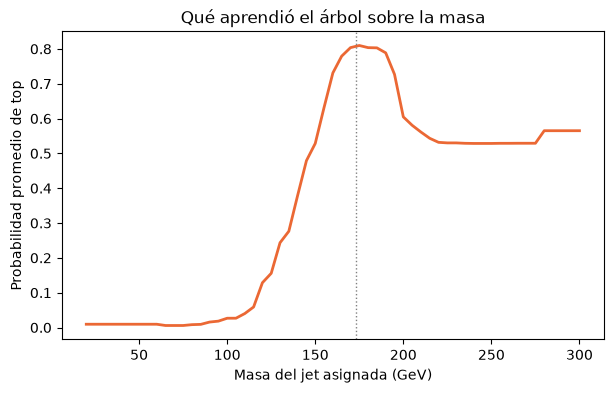

In [15]:
masas = np.linspace(20, 300, 57)
muestra = Xa_pru[:3000].copy()          # 3 mil jets de prueba

respuesta = []
for m in masas:
    muestra[:, 0] = m                   # columna 0 = masa; las otras quedan igual
    respuesta.append(arbol.predict_proba(muestra)[:, 1].mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(masas, respuesta, color="#eb6834", lw=2)
ax.axvline(173, color="gray", ls=":", lw=1)
ax.set_xlabel("Masa del jet asignada (GeV)")
ax.set_ylabel("Probabilidad promedio de top")
ax.set_title("Qué aprendió el árbol sobre la masa")
plt.show()

In [16]:
N = 80   # partículas por jet que le daremos a la red

# Fracción de energía de cada partícula, y su logaritmo (0 en el relleno)
z = pt_i[:, :N] / pt_total[:, None]
with np.errstate(divide="ignore"):
    log_z = np.where(hay[:, :N], np.log(z), 0.0)

# Tabla de entrada: (jets, partículas, 3 cantidades), en float32 para ahorrar memoria
X_part = np.stack([log_z, deta[:, :N], dphi[:, :N]], axis=-1).astype(np.float32)
mascara = hay[:, :N]

# ¿Cuánta energía conservamos con 50 partículas?
frac_energia = pt_i[:, :N].sum(axis=1) / pt_total
print(f"Forma de la entrada: {X_part.shape}")
print(f"Memoria: {X_part.nbytes / 1e6:.0f} MB")
print(f"Energía conservada, en promedio:    {frac_energia.mean():.4f}")
print(f"Energía conservada, en el peor jet: {frac_energia.min():.4f}")
print(f"Jets con más de {N} partículas: {(n_part > N).mean():.1%}")

Forma de la entrada: (100000, 80, 3)
Memoria: 96 MB
Energía conservada, en promedio:    0.9996
Energía conservada, en el peor jet: 0.8896
Jets con más de 80 partículas: 4.2%


In [17]:
# 1. ¿Vienen ordenadas por pT? (cada partícula real con pT menor o igual que la anterior)
reales_seguidas = hay[:, 1:] & hay[:, :-1]
ordenadas = (pt_i[:, 1:] <= pt_i[:, :-1] + 1e-6) | ~reales_seguidas
print(f"Parejas consecutivas bien ordenadas por pT: {ordenadas.mean():.4f}")

# 2. ¿Cuántos jets pierden mucho, y de qué clase son?
for N_prueba in [50, 80, 100]:
    conservada = pt_i[:, :N_prueba].sum(axis=1) / pt_total
    print(f"\nCon {N_prueba} partículas:")
    for umbral in [0.99, 0.95, 0.90]:
        pierden = conservada < umbral
        print(f"  conservan menos del {umbral:.0%}: {pierden.mean():6.2%} de los jets  "
              f"(top {pierden[y == 1].mean():6.2%}, QCD {pierden[y == 0].mean():6.2%})")

Parejas consecutivas bien ordenadas por pT: 1.0000

Con 50 partículas:
  conservan menos del 99%: 24.31% de los jets  (top 31.13%, QCD 17.63%)
  conservan menos del 95%:  4.83% de los jets  (top  5.56%, QCD  4.11%)
  conservan menos del 90%:  0.83% de los jets  (top  0.77%, QCD  0.90%)

Con 80 partículas:
  conservan menos del 99%:  1.26% de los jets  (top  1.23%, QCD  1.30%)
  conservan menos del 95%:  0.07% de los jets  (top  0.03%, QCD  0.10%)
  conservan menos del 90%:  0.00% de los jets  (top  0.00%, QCD  0.00%)

Con 100 partículas:
  conservan menos del 99%:  0.10% de los jets  (top  0.05%, QCD  0.14%)
  conservan menos del 95%:  0.00% de los jets  (top  0.00%, QCD  0.00%)
  conservan menos del 90%:  0.00% de los jets  (top  0.00%, QCD  0.00%)


In [18]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --- Datos: MISMO reparto que los modelos anteriores ---
indices = np.arange(len(y))
idx_ent, idx_pru = train_test_split(indices, test_size=0.3, random_state=42, stratify=y)

def a_tensores(idx):
    return (torch.from_numpy(X_part[idx]),
            torch.from_numpy(mascara[idx].astype(np.float32)),
            torch.from_numpy(y[idx].astype(np.float32)))

Xp_ent, m_ent, yp_ent = a_tensores(idx_ent)
Xp_pru, m_pru, yp_pru = a_tensores(idx_pru)
print("¿Mismo reparto?", np.array_equal(y[idx_pru], y_pru))

# --- La red ---
class RedFlujoParticulas(nn.Module):
    def __init__(self, n_pistas=64):
        super().__init__()
        self.phi = nn.Sequential(          # mira UNA partícula
            nn.Linear(3, 64), nn.ReLU(),
            nn.Linear(64, n_pistas), nn.ReLU(),
        )
        self.F = nn.Sequential(            # mira las pistas sumadas del jet
            nn.Linear(n_pistas, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x, mascara):
        por_particula = self.phi(x)                          # (jets, 80, 64)
        por_particula = por_particula * mascara[..., None]   # el relleno aporta 0
        pistas = por_particula.sum(dim=1)                    # (jets, 64): ¡la suma!
        return self.F(pistas).squeeze(-1)                    # un número por jet

red = RedFlujoParticulas()
print(red)

# Prueba de que no depende del orden: barajamos las partículas de 5 jets
x5, m5 = Xp_pru[:5], m_pru[:5]
perm = torch.randperm(80)
print("Salida original: ", red(x5, m5).detach().numpy().round(4))
print("Salida barajada: ", red(x5[:, perm], m5[:, perm]).detach().numpy().round(4))

¿Mismo reparto? True
RedFlujoParticulas(
  (phi): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (F): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
Salida original:  [1.1964 2.3613 2.3237 1.9475 2.271 ]
Salida barajada:  [1.1964 2.3613 2.3237 1.9475 2.271 ]


In [19]:
from torch.utils.data import TensorDataset, DataLoader
import time

# Separar validación (dentro del entrenamiento; la prueba no se toca)
gen = torch.Generator().manual_seed(0)
orden = torch.randperm(len(yp_ent), generator=gen)
i_val, i_tr = orden[:7000], orden[7000:]

cargador = DataLoader(
    TensorDataset(Xp_ent[i_tr], m_ent[i_tr], yp_ent[i_tr]),
    batch_size=256, shuffle=True,
)

red = RedFlujoParticulas()                       # red nueva, pesos al azar
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
perdida_fn = nn.BCEWithLogitsLoss()

def auc_validacion():
    red.eval()
    with torch.no_grad():
        s = red(Xp_ent[i_val], m_ent[i_val]).numpy()
    red.train()
    return roc_auc_score(yp_ent[i_val].numpy(), s)

for epoca in range(15):
    t0, suma, n = time.time(), 0.0, 0
    for xb, mb, yb in cargador:
        optimizador.zero_grad()                  # borrar las derivadas del paso anterior
        perdida = perdida_fn(red(xb, mb), yb)    # qué tan mal va en este lote
        perdida.backward()                       # calcular las derivadas
        optimizador.step()                       # dar el paso cuesta abajo
        suma += perdida.item() * len(yb); n += len(yb)
    print(f"época {epoca+1:2d}   pérdida {suma/n:.4f}   "
          f"AUC validación {auc_validacion():.4f}   ({time.time()-t0:.0f} s)")

época  1   pérdida 0.6179   AUC validación 0.8654   (4 s)
época  2   pérdida 0.4401   AUC validación 0.9107   (4 s)
época  3   pérdida 0.3928   AUC validación 0.9179   (4 s)
época  4   pérdida 0.3695   AUC validación 0.9163   (4 s)
época  5   pérdida 0.3570   AUC validación 0.9256   (4 s)
época  6   pérdida 0.3348   AUC validación 0.9282   (4 s)
época  7   pérdida 0.3140   AUC validación 0.9311   (4 s)
época  8   pérdida 0.2968   AUC validación 0.9411   (4 s)
época  9   pérdida 0.2882   AUC validación 0.9435   (4 s)
época 10   pérdida 0.2837   AUC validación 0.9450   (4 s)
época 11   pérdida 0.2762   AUC validación 0.9419   (4 s)
época 12   pérdida 0.2777   AUC validación 0.9477   (4 s)
época 13   pérdida 0.2709   AUC validación 0.9486   (4 s)
época 14   pérdida 0.2697   AUC validación 0.9396   (4 s)
época 15   pérdida 0.2676   AUC validación 0.9426   (5 s)


In [20]:
import copy

# A. Estandarizar con las partículas REALES del entrenamiento
reales = m_ent[i_tr].bool()
valores = Xp_ent[i_tr][reales]                 # (n_partículas_reales, 3)
media, desv = valores.mean(0), valores.std(0)
print("Antes de estandarizar  -> media:", media.numpy().round(2), " desv:", desv.numpy().round(2))

def estandarizar(x, m):
    return ((x - media) / desv) * m[..., None]  # el relleno queda en 0

Xs_ent = estandarizar(Xp_ent, m_ent)
Xs_pru = estandarizar(Xp_pru, m_pru)

cargador = DataLoader(
    TensorDataset(Xs_ent[i_tr], m_ent[i_tr], yp_ent[i_tr]),
    batch_size=256, shuffle=True,
)

torch.manual_seed(42)
red = RedFlujoParticulas()
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
# B. Si la validación no mejora en 2 épocas, el paso se reduce a la mitad
ajuste_paso = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=0.5, patience=2)

def auc_validacion():
    red.eval()
    with torch.no_grad():
        s = red(Xs_ent[i_val], m_ent[i_val]).numpy()
    red.train()
    return roc_auc_score(yp_ent[i_val].numpy(), s)

mejor_auc, mejor_estado = 0.0, None
for epoca in range(30):
    t0, suma, n = time.time(), 0.0, 0
    for xb, mb, yb in cargador:
        optimizador.zero_grad()
        perdida = perdida_fn(red(xb, mb), yb)
        perdida.backward()
        optimizador.step()
        suma += perdida.item() * len(yb); n += len(yb)

    auc_v = auc_validacion()
    ajuste_paso.step(auc_v)
    marca = ""
    if auc_v > mejor_auc:                       # C. guardar la mejor
        mejor_auc, mejor_estado = auc_v, copy.deepcopy(red.state_dict())
        marca = "  ← mejor"
    paso = optimizador.param_groups[0]["lr"]
    print(f"época {epoca+1:2d}   pérdida {suma/n:.4f}   AUC val {auc_v:.4f}   paso {paso:.0e}{marca}")

red.load_state_dict(mejor_estado)
print(f"\nMejor AUC de validación: {mejor_auc:.4f}")

Antes de estandarizar  -> media: [-5.05  0.   -0.  ]  desv: [1.46 0.27 0.27]
época  1   pérdida 0.4103   AUC val 0.9296   paso 1e-03  ← mejor
época  2   pérdida 0.2901   AUC val 0.9459   paso 1e-03  ← mejor
época  3   pérdida 0.2729   AUC val 0.9518   paso 1e-03  ← mejor
época  4   pérdida 0.2639   AUC val 0.9549   paso 1e-03  ← mejor
época  5   pérdida 0.2575   AUC val 0.9584   paso 1e-03  ← mejor
época  6   pérdida 0.2493   AUC val 0.9628   paso 1e-03  ← mejor
época  7   pérdida 0.2421   AUC val 0.9655   paso 1e-03  ← mejor
época  8   pérdida 0.2362   AUC val 0.9660   paso 1e-03  ← mejor
época  9   pérdida 0.2306   AUC val 0.9652   paso 1e-03
época 10   pérdida 0.2279   AUC val 0.9695   paso 1e-03  ← mejor
época 11   pérdida 0.2228   AUC val 0.9698   paso 1e-03  ← mejor
época 12   pérdida 0.2178   AUC val 0.9701   paso 1e-03  ← mejor
época 13   pérdida 0.2164   AUC val 0.9708   paso 1e-03  ← mejor
época 14   pérdida 0.2119   AUC val 0.9720   paso 1e-03  ← mejor
época 15   pérdida 0.2

Modelo                     AUC   Rechazo al 30%
Solo masa                0.929               48
Regresión logística      0.949               66
Árbol potenciado         0.957               99
Red de partículas        0.975              389


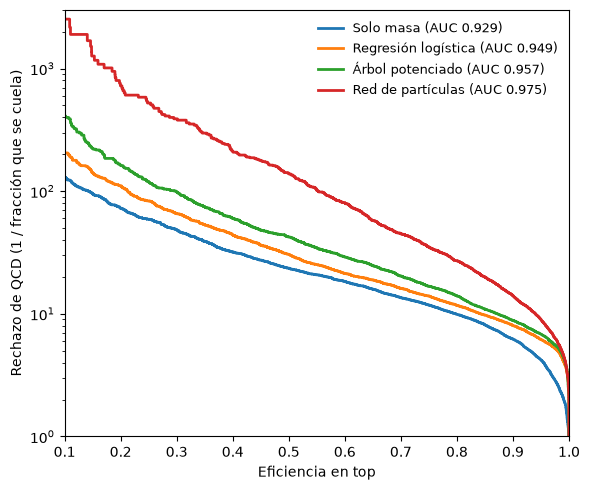

In [21]:
from sklearn.metrics import roc_curve

# Probabilidades de la red en los jets de prueba
red.eval()
with torch.no_grad():
    s_red = red(Xs_pru, m_pru).numpy()

modelos = {
    "Solo masa":           -X_pru[:, 0],
    "Regresión logística": prob_top,
    "Árbol potenciado":    prob_arbol,
    "Red de partículas":   s_red,
}

def rechazo_al_30(y_verdad, puntaje):
    fpr, tpr, _ = roc_curve(y_verdad, puntaje)
    return 1 / np.interp(0.30, tpr, fpr)

fig, ax = plt.subplots(figsize=(6, 5))
print(f"{'Modelo':22s}  {'AUC':>6s}  {'Rechazo al 30%':>15s}")
for nombre, puntaje in modelos.items():
    auc = roc_auc_score(y_pru, puntaje)
    rech = rechazo_al_30(y_pru, puntaje)
    print(f"{nombre:22s}  {auc:6.3f}  {rech:15.0f}")
    fpr, tpr, _ = roc_curve(y_pru, puntaje)
    ax.plot(tpr, 1 / np.maximum(fpr, 1e-6), lw=2, label=f"{nombre} (AUC {auc:.3f})")

ax.set_yscale("log")
ax.set_xlim(0.1, 1.0)
ax.set_ylim(1, 3000)
ax.set_xlabel("Eficiencia en top")
ax.set_ylabel("Rechazo de QCD (1 / fracción que se cuela)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("../figures/comparacion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

Jets en desacuerdo: 1888 de 30000 (6.3%)
En los desacuerdos, la red acierta el 64% y el árbol el 36%

Impostores atrapados solo por la red: 947


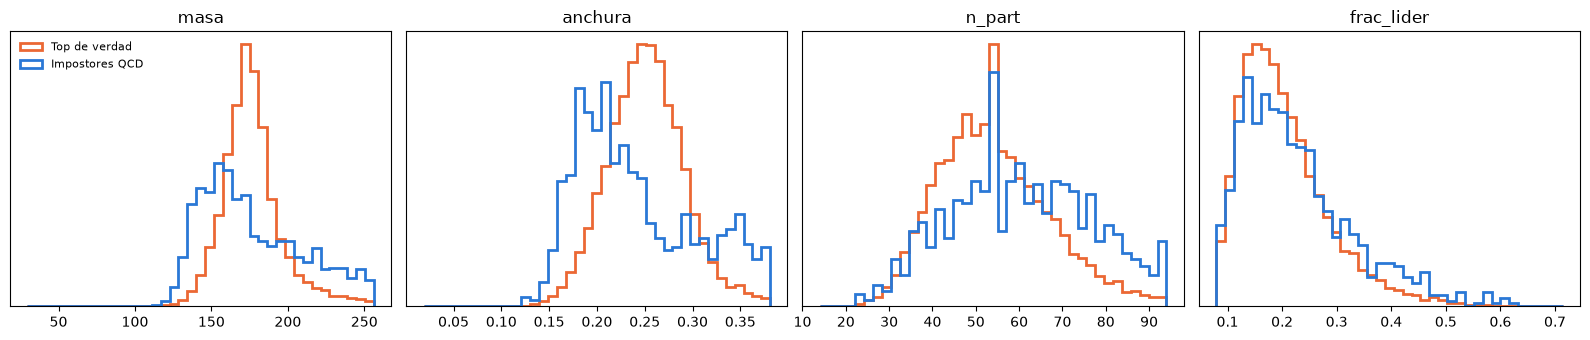

In [22]:
# Probabilidades de los dos modelos sobre los MISMOS jets de prueba
p_arbol = prob_arbol
p_red = 1 / (1 + np.exp(-s_red))       # la red da un número cualquiera; la curva en S lo vuelve probabilidad
verdad_top = (y_pru == 1)

arbol_top = p_arbol > 0.5
red_top = p_red > 0.5

# Paso 1: ¿dónde no están de acuerdo, y quién acierta?
desacuerdo = arbol_top != red_top
acierta_red = (red_top == verdad_top)[desacuerdo].mean()
print(f"Jets en desacuerdo: {desacuerdo.sum()} de {len(y_pru)} ({desacuerdo.mean():.1%})")
print(f"En los desacuerdos, la red acierta el {acierta_red:.0%} y el árbol el {1 - acierta_red:.0%}")

# Paso 2: impostores que solo la red atrapó, contra top de verdad que ambos reconocen
impostores = (~verdad_top) & arbol_top & (~red_top)
top_seguros = verdad_top & arbol_top & red_top
print(f"\nImpostores atrapados solo por la red: {impostores.sum()}")

fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))
for k, (ax, nombre) in enumerate(zip(ejes, nombres_arbol)):
    valores = Xa_pru[:, k]
    rango = np.percentile(valores, [1, 99])
    bins = np.linspace(*rango, 40)
    ax.hist(valores[top_seguros], bins, histtype="step", lw=2, color="#eb6834", density=True, label="Top de verdad")
    ax.hist(valores[impostores], bins, histtype="step", lw=2, color="#2a78d6", density=True, label="Impostores QCD")
    ax.set_title(nombre)
    ax.set_yticks([])
ejes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
malos = ~np.isfinite(tau32)
print(f"Jets con τ3/τ2 inválido: {malos.sum()} de {len(y)}")
print("τ1:", taus[1][malos][:8].round(4))
print("τ2:", taus[2][malos][:8].round(4))
print("τ3:", taus[3][malos][:8].round(4))
print("Partículas reales:", n_part[malos][:8])
print("Fracción que son top:", y[malos].mean().round(2))

# Las posiciones de las partículas de uno de esos jets
j = np.flatnonzero(malos)[0]
reales = hay[j, :P]
print("\nPrimer jet raro, sus partículas (Δη, Δφ, energía):")
print(np.column_stack([deta[j, :P][reales], dphi[j, :P][reales], w_todo[j][reales]]).round(3)[:15])

Jets con τ3/τ2 inválido: 3 de 100000
τ1: [0. 0. 0.]
τ2: [0. 0. 0.]
τ3: [0. 0. 0.]
Partículas reales: [1 1 1]
Fracción que son top: 0.0

Primer jet raro, sus partículas (Δη, Δφ, energía):
[[0. 0. 1.]]


AUC de τ3/τ2 sola: 0.850  (menor = más top)


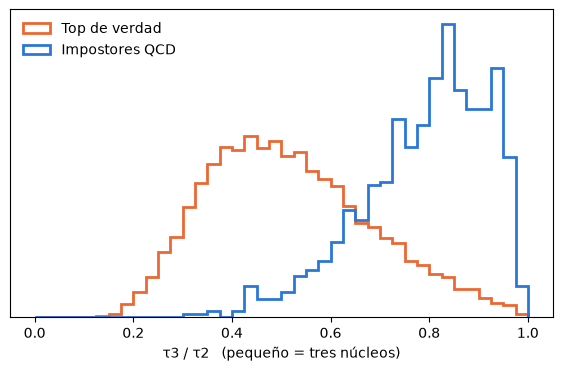

In [25]:
def tau_N(pos, w, N, vueltas=10):
    """pos: (jets, partículas, 2) con (Δη, Δφ);  w: (jets, partículas) fracción de energía, 0 en el relleno."""
    J = pos.shape[0]
    filas = np.arange(J)

    # Centros iniciales: el más energético, y luego el más lejano (pesado por energía)
    centros = np.zeros((J, N, 2))
    centros[:, 0] = pos[:, 0]
    for k in range(1, N):
        d2 = ((pos[:, :, None, :] - centros[:, None, :k, :]) ** 2).sum(-1).min(-1)   # (jets, partículas)
        centros[:, k] = pos[filas, np.argmax(w * d2, axis=1)]

    for _ in range(vueltas):
        d = np.sqrt(((pos[:, :, None, :] - centros[:, None, :, :]) ** 2).sum(-1))   # (jets, partículas, N)
        asignado = np.eye(N)[d.argmin(-1)] * w[..., None]                          # peso de cada partícula en cada centro
        peso_centro = asignado.sum(1)                                              # (jets, N)
        nuevos = (asignado[..., None] * pos[:, :, None, :]).sum(1) / np.maximum(peso_centro, 1e-12)[..., None]
        centros = np.where(peso_centro[..., None] > 0, nuevos, centros)

    d = np.sqrt(((pos[:, :, None, :] - centros[:, None, :, :]) ** 2).sum(-1))
    return (w * d.min(-1)).sum(1) / w.sum(1)


P = 80
pos_todo = np.stack([deta[:, :P], dphi[:, :P]], axis=-1)
w_todo = np.where(hay[:, :P], pt_i[:, :P], 0.0) / pt_total[:, None]

taus = {N: np.zeros(len(y)) for N in (1, 2, 3)}
for a in range(0, len(y), 10_000):                 # de a 10 mil jets, para cuidar la memoria
    for N in (1, 2, 3):
        taus[N][a:a + 10_000] = tau_N(pos_todo[a:a + 10_000], w_todo[a:a + 10_000], N)

tau32 = np.where(taus[2] > 0, taus[3] / np.where(taus[2] > 0, taus[2], 1), 1.0)
print(f"AUC de τ3/τ2 sola: {1 - roc_auc_score(y, tau32):.3f}  (menor = más top)")

# ¿Los impostores tienen τ3/τ2 más alto que los top de verdad?
t32_pru = tau32[idx_pru]
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(t32_pru[top_seguros], bins, histtype="step", lw=2, color="#eb6834", density=True, label="Top de verdad")
ax.hist(t32_pru[impostores], bins, histtype="step", lw=2, color="#2a78d6", density=True, label="Impostores QCD")
ax.set_xlabel("τ3 / τ2   (pequeño = tres núcleos)")
ax.set_yticks([])
ax.legend(frameon=False)
plt.show()

In [26]:
# τ2/τ1, con el mismo cuidado para los jets de una partícula
tau21 = np.where(taus[1] > 0, taus[2] / np.where(taus[1] > 0, taus[1], 1), 1.0)

nombres_6 = ["masa", "anchura", "n_part", "frac_lider", "tau32", "tau21"]
X6 = np.column_stack([jet_masa, anchura, n_part, frac_lider, tau32, tau21])

X6_ent, X6_pru, y6_ent, y6_pru = train_test_split(
    X6, y, test_size=0.3, random_state=42, stratify=y
)
print("¿Mismo reparto?", np.array_equal(y6_pru, y_pru))

arbol6 = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42)
arbol6.fit(X6_ent, y6_ent)
prob_arbol6 = arbol6.predict_proba(X6_pru)[:, 1]

modelos["Árbol + τ (6 pistas)"] = prob_arbol6
print(f"\n{'Modelo':22s}  {'AUC':>6s}  {'Rechazo al 30%':>15s}")
for nombre, puntaje in modelos.items():
    print(f"{nombre:22s}  {roc_auc_score(y_pru, puntaje):6.3f}  {rechazo_al_30(y_pru, puntaje):15.0f}")

¿Mismo reparto? True

Modelo                     AUC   Rechazo al 30%
Solo masa                0.929               48
Regresión logística      0.949               66
Árbol potenciado         0.957               99
Red de partículas        0.975              389
Árbol + τ (6 pistas)     0.978              892
